# Double-chain Fermi-Hubbard: test notebook

One Hamiltonian (`hamiltonian.py`): a length `N` (qubits per chain) plus a coefficient for each term in `TERMS`.
The two encodings are just two models of different length with different terms switched on:

- **jw**: `N = L`, `*_site` terms, a particle is a qubit in |1> (`count="site"`)
- **dw**: `N = L+1`, `*_wall` terms, a particle is a domain wall (`count="wall"`)

Parameters come from `config.yaml`. Sections:
1. Analytic checks
2. jw vs dw equivalence (exact and approximate DW)
3. Ground state in a sector
4. Time evolution with QiliSim

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace
from itertools import product
from scipy.sparse.linalg import expm_multiply
import qilisdk

from hamiltonian import Physics, Model, TERMS, term, load_config, occupation, number_op, UP, DN
from statics import matrix, diagonal, sector, edge_sector, lowest_states, spectrum, site_profile
from dynamics import initial_state, evolve

print("qilisdk", qilisdk.__version__)

cfg = load_config("config.yaml")
phys = Physics(**cfg["physics"])
models = {enc: Model.from_physics(phys, enc) for enc in ("jw", "dw")}
COUNT = {"jw": "site", "dw": "wall"}          # what a particle is in each encoding

for enc, m in models.items():
    print(f"{enc}: {m}")

qilisdk 0.3.1
jw: Model(N=4, coefficients={'hop_site': -1.0, 'nn_site': 4.0})
dw: Model(N=5, coefficients={'hop_wall': -1.0, 'nn_wall': 4.0})


Every term written out on a short chain (`N = 3`, qubits 0-2 up, 3-5 down), to check against the docstring of `hamiltonian.py`.

In [2]:
for name in TERMS:
    print(f"{name:>12}: {term(name, 3)}")

    hop_site: 0.5 X(0) X(1) + 0.5 Y(0) Y(1) + 0.5 X(1) X(2) + 0.5 Y(1) Y(2) + 0.5 X(3) X(4) + 0.5 Y(3) Y(4) + 0.5 X(4) X(5) + 0.5 Y(4) Y(5)
    hop_wall: 0.5 X(1) - 0.5 Z(0) X(1) Z(2) + 0.5 X(4) - 0.5 Z(3) X(4) Z(5)
      n_site: 3 - 0.5 Z(0) - 0.5 Z(1) - 0.5 Z(2) - 0.5 Z(3) - 0.5 Z(4) - 0.5 Z(5)
      n_wall: 2 - 0.5 Z(0) Z(1) - 0.5 Z(1) Z(2) - 0.5 Z(3) Z(4) - 0.5 Z(4) Z(5)
     nn_site: 0.75 - 0.25 Z(3) - 0.25 Z(0) + 0.25 Z(0) Z(3) - 0.25 Z(4) - 0.25 Z(1) + 0.25 Z(1) Z(4) - 0.25 Z(5) - 0.25 Z(2) + 0.25 Z(2) Z(5)
     nn_wall: 0.5 - 0.25 Z(3) Z(4) - 0.25 Z(0) Z(1) + 0.25 Z(0) Z(1) Z(3) Z(4) - 0.25 Z(4) Z(5) - 0.25 Z(1) Z(2) + 0.25 Z(1) Z(2) Z(4) Z(5)
 eta_nn_site: 0.25 - 0.25 Z(3) - 0.25 Z(0) + 0.5 Z(0) Z(3) - 0.25 Z(0) Z(3) Z(4) - 0.25 Z(0) Z(1) Z(3) + 0.5 Z(0) Z(1) Z(3) Z(4) - 0.25 Z(0) Z(1) Z(3) Z(4) Z(5) - 0.25 Z(0) Z(1) Z(2) Z(3) Z(4) + 0.25 Z(0) Z(1) Z(2) Z(3) Z(4) Z(5)
 eta_nn_wall: 0.25 Z(0) Z(3) - 0.25 Z(0) Z(4) - 0.25 Z(1) Z(3) + 0.5 Z(1) Z(4) - 0.25 Z(1) Z(5) - 0.25 Z(2) Z(

## 1. Analytic checks

**1a.** At U = 0 the ground-state energy of sector (N_up, N_dn) is the sum of the lowest single-particle levels
$\varepsilon_k = -2t\cos\big(\pi k/(L+1)\big)$, $k = 1..L$ (open chain).

**1b.** Two sites, one up and one down particle: $E_0 = \big(U - \sqrt{U^2 + 16t^2}\big)/2$.

In [3]:
L, t, U = phys.L, phys.t, phys.U
eps = np.sort(-2 * t * np.cos(np.pi * np.arange(1, L + 1) / (L + 1)))

free = replace(phys, U=0, U_eta=0, h=0, mu=0)
for enc in ("jw", "dw"):
    m = Model.from_physics(free, enc)
    H = matrix(m.hamiltonian(), m.nqubits)
    err = max(abs(lowest_states(H, sector(m, Nu, Nd, COUNT[enc]))[0][0] - eps[:Nu].sum() - eps[:Nd].sum())
              for Nu, Nd in product(range(L + 1), repeat=2))
    print(f"1a {enc}: max |E0 - free fermions| over all sectors = {err:.1e}")

exact = (U - np.sqrt(U**2 + 16 * t**2)) / 2
for enc in ("jw", "dw"):
    m = Model.from_physics(Physics(L=2, t=t, U=U), enc)
    E0 = lowest_states(matrix(m.hamiltonian(), m.nqubits), sector(m, 1, 1, COUNT[enc]))[0][0]
    print(f"1b {enc}: E0 = {E0:.12f}   exact = {exact:.12f}")

1a jw: max |E0 - free fermions| over all sectors = 3.6e-15


1a dw: max |E0 - free fermions| over all sectors = 4.4e-15
1b jw: E0 = -0.828427124746   exact = -0.828427124746
1b dw: E0 = -0.828427124746   exact = -0.828427124746


## 2. jw vs dw equivalence

**2a. Exact DW model.** For each coupling on its own (and all together), both signs of b, every sector (N_up, N_dn):
the jw and dw spectra must agree to machine precision.
With wall counting the sector also fixes the left edge qubits (Z_0,up = +1, Z_0,dn = b).

In [4]:
c = cfg["checks"]
L = c["L"]
cases = {"t only": {}, **{k: {k: v} for k, v in c["couplings"].items()}, "all": c["couplings"]}

print(f"{'couplings':>9} {'b':>3}   max|E_jw - E_dw| over all sectors")
for name, couplings in cases.items():
    for b in (1, -1):
        p = Physics(L=L, b=b, **couplings)
        jw, dw = Model.from_physics(p, "jw"), Model.from_physics(p, "dw")
        Hj, Hd = matrix(jw.hamiltonian(), jw.nqubits), matrix(dw.hamiltonian(), dw.nqubits)
        err = max(np.max(np.abs(spectrum(Hj, sector(jw, Nu, Nd, "site"))
                                - spectrum(Hd, sector(dw, Nu, Nd, "wall", b))))
                  for Nu, Nd in product(range(L + 1), repeat=2))
        print(f"{name:>9} {b:+3d}   {err:.1e}")

couplings   b   max|E_jw - E_dw| over all sectors


   t only  +1   8.9e-16


   t only  -1   2.7e-15


        U  +1   2.7e-15


        U  -1   2.7e-15
    U_eta  +1   2.7e-15


    U_eta  -1   4.9e-15
        h  +1   2.7e-15


        h  -1   1.8e-15
       mu  +1   8.9e-16


       mu  -1   1.3e-15


      all  +1   3.6e-15


      all  -1   3.1e-15


**2b. Approximate DW model.** Same dw model with `hop_wall` switched off and `x_field = -Gamma`, `zz_chain = J` switched on.
Edge qubits never flip, so each N_s is conserved only mod 2 (`edge_sector`).
Eigenstates are assigned to the target sector by their <N_s>, and the constant J offset
J Σ_s (L − 2N_s) is subtracted. The error against the exact model with t = Gamma should fall as Gamma²/|J|.

J =   -5.0: 9 states, max |E_approx - E_exact| = 1.053e-01
J =  -10.0: 9 states, max |E_approx - E_exact| = 5.132e-02
J =  -20.0: 9 states, max |E_approx - E_exact| = 2.533e-02
J =  -40.0: 9 states, max |E_approx - E_exact| = 1.258e-02


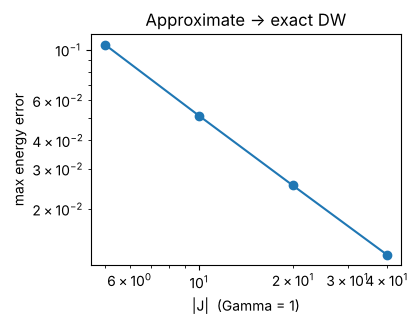

In [5]:
a = c["approximate_dw"]
L, Nu, Nd, Gamma = a["L"], a["N_up"], a["N_dn"], a["Gamma"]

exact = Model.from_physics(Physics(L=L, t=Gamma), "dw")
E_exact = spectrum(matrix(exact.hamiltonian(), exact.nqubits), sector(exact, Nu, Nd, "wall"))

errors = []
for J in a["J_values"]:
    approx = Model(exact.N, {**exact.coefficients, "hop_wall": 0, "x_field": -Gamma, "zz_chain": J})
    idx = edge_sector(approx, Nu, Nd)
    E, V = np.linalg.eigh(matrix(approx.hamiltonian(), approx.nqubits)[idx][:, idx].toarray())
    weights = np.abs(V) ** 2
    n_up = diagonal(number_op(approx.N, UP, "wall"), approx.nqubits)[idx] @ weights
    n_dn = diagonal(number_op(approx.N, DN, "wall"), approx.nqubits)[idx] @ weights
    keep = (np.abs(n_up - Nu) < 0.5) & (np.abs(n_dn - Nd) < 0.5)
    E_approx = np.sort(E[keep]) - J * (2 * L - 2 * (Nu + Nd))
    errors.append(np.max(np.abs(E_approx - E_exact)))
    print(f"J = {J:+6.1f}: {keep.sum()} states, max |E_approx - E_exact| = {errors[-1]:.3e}")

plt.figure(figsize=(4, 3))
plt.loglog(np.abs(a["J_values"]), errors, "o-")
plt.xlabel("|J|  (Gamma = 1)"); plt.ylabel("max energy error")
plt.title("Approximate -> exact DW"); plt.show()

## 3. Ground state in a sector

Lowest `n_states` energies in sector (N_up, N_dn) from `config.yaml`, and the site profile of the ground state.
Both encodings must agree (if the ground state is degenerate, the profiles can differ by the choice of basis).

In [6]:
s = cfg["statics"]
for enc, m in models.items():
    H = matrix(m.hamiltonian(), m.nqubits)
    E, psi = lowest_states(H, sector(m, s["N_up"], s["N_dn"], COUNT[enc], phys.b), k=s["n_states"])
    print(f"{enc}: E = {np.round(E, 8)}")
    for key, val in site_profile(m, psi[:, 0], COUNT[enc], phys.b).items():
        print(f"   {key:>6}: {np.round(val, 6)}")

jw: E = [-1.95314531 -1.4128987  -0.85952339 -0.59540969]
     n_up: [0.5 0.5 0.5 0.5]
     n_dn: [0.5 0.5 0.5 0.5]
   double: [0.07281  0.096983 0.096983 0.07281 ]
      eta: [ 1.       -0.708761  0.844116 -0.708761]
dw: E = [-1.95314531 -1.4128987  -0.85952339 -0.59540969]
     n_up: [0.5 0.5 0.5 0.5]
     n_dn: [0.5 0.5 0.5 0.5]
   double: [0.07281  0.096983 0.096983 0.07281 ]
      eta: [ 1.       -0.708761  0.844116 -0.708761]


## 4. Time evolution with QiliSim

Initial state from `config.yaml` (a superposition of Fock states), evolved under the constant H.
QiliSim is cross-checked against exact exponentiation (`scipy expm_multiply`), and jw against dw.

In [7]:
d = cfg["dynamics"]
results = {}
for enc, m in models.items():
    psi0 = initial_state(m, d["initial_state"], COUNT[enc], phys.b)
    obs = [occupation(m.N, k, s, COUNT[enc]) for s in (UP, DN) for k in range(phys.L)]
    times, n = evolve(m, psi0, obs, d["T"], d["dt"])
    results[enc] = n

    # cross-check against exact exponentiation
    v0 = np.asarray(psi0.dense()).ravel()
    states = expm_multiply(-1j * matrix(m.hamiltonian(), m.nqubits), v0,
                           start=0, stop=d["T"], num=len(times), endpoint=True)
    obs_mats = [matrix(o, m.nqubits) for o in obs]
    n_exact = np.array([[np.real(np.vdot(v, M @ v)) for M in obs_mats] for v in states])
    print(f"{enc}: max |QiliSim - expm| = {np.max(np.abs(n - n_exact)):.1e}")

print(f"max |n_jw - n_dw| = {np.max(np.abs(results['jw'] - results['dw'])):.1e}")

jw: max |QiliSim - expm| = 3.8e-05
dw: max |QiliSim - expm| = 3.8e-05
max |n_jw - n_dw| = 6.7e-16


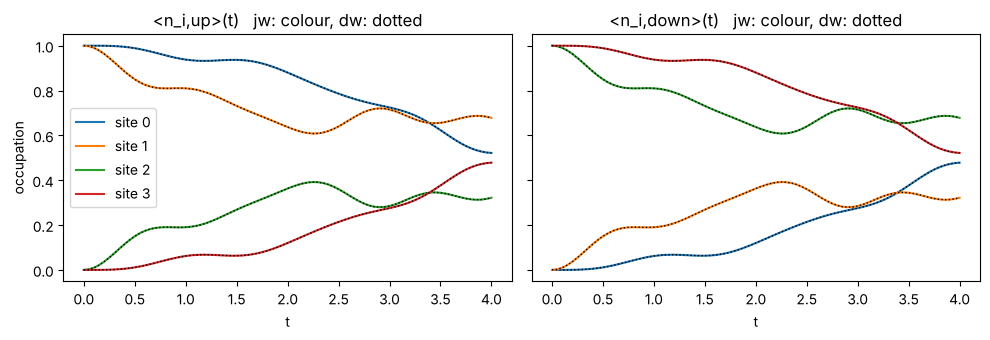

In [8]:
L = phys.L
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (s, name) in zip(axes, ((UP, "up"), (DN, "down"))):
    for i in range(L):
        ax.plot(times, results["jw"][:, s * L + i], label=f"site {i}")
        ax.plot(times, results["dw"][:, s * L + i], "k:", lw=1)
    ax.set_title(f"<n_i,{name}>(t)   jw: colour, dw: dotted")
    ax.set_xlabel("t")
axes[0].set_ylabel("occupation")
axes[0].legend()
plt.tight_layout(); plt.show()